# CSC60904 Deep Learning — Individual Assignment (30%)
## CIFARInception: Custom Inception-Style Architecture for CIFAR-10

      
MAZEN HOSSAMELDIN HASSAN TAWFIK MEHNA


In [1]:
# Unziping the official CIFAR-10 archive
import tarfile, os

ARCHIVE_PATH = "cifar-10-python.tar.gz"
EXTRACT_DIR = "."

if os.path.exists(ARCHIVE_PATH) and not os.path.exists("cifar-10-batches-py"):
    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        tar.extractall(EXTRACT_DIR, filter="data")
    print("Extracted cifar-10-batches-py/")
elif os.path.exists("cifar-10-batches-py"):
    print("Already extracted.")
else:
    print("cifar-10-python.tar.gz not found — upload it before continuing.")


cifar-10-python.tar.gz not found — upload it before continuing.



## PART 1 — Supporting Code: Figure 1 (Gradient Magnitude vs. Depth)



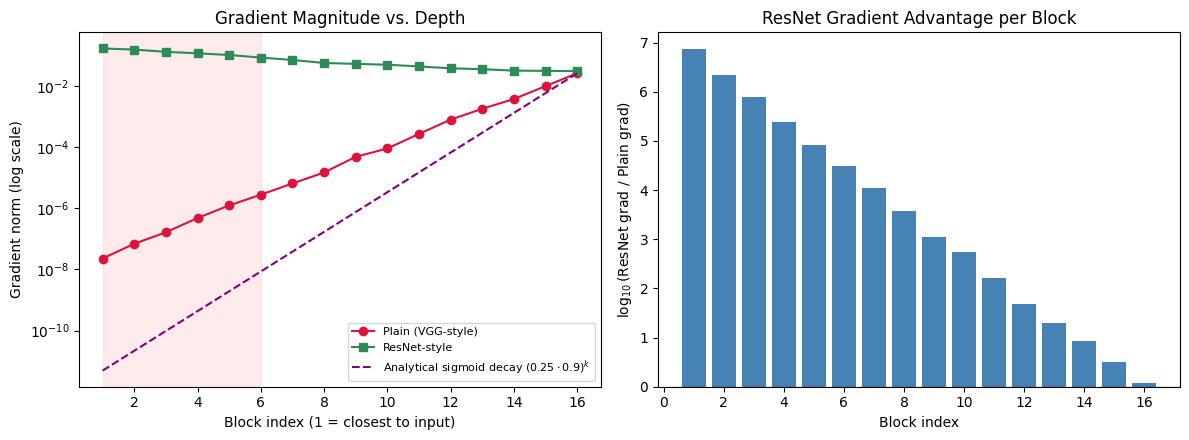

Plain net decay ratio (block1/block16): 8.84e-07
ResNet decay ratio (block1/block16):   5.50e+00


In [ ]:
import torch, torch.nn as nn, numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
DEPTH = 16

class PlainBlock(nn.Module):
    """One 'VGG-style' block: Conv -> ReLU, no shortcut."""
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return torch.relu(self.conv(x))

class ResBlock(nn.Module):
    """One residual block: x + ReLU(Conv(x))  — identity shortcut."""
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return x + torch.relu(self.conv(x))

class ToyNet(nn.Module):
    def __init__(self, block_cls, depth, ch=16):
        super().__init__()
        self.blocks = nn.ModuleList([block_cls(ch) for _ in range(depth)])
        self.head = nn.Linear(ch, 10)
    def forward(self, x):
        acts = []
        for b in self.blocks:
            x = b(x)
            x.retain_grad()
            acts.append(x)
        return self.head(x.mean(dim=[2, 3])), acts

def grad_norms(block_cls, seed=1):
    torch.manual_seed(seed)
    net = ToyNet(block_cls, DEPTH)
    x = torch.randn(8, 16, 8, 8)
    out, acts = net(x)
    loss = nn.CrossEntropyLoss()(out, torch.randint(0, 10, (8,)))
    loss.backward()
    return np.array([a.grad.norm().item() for a in acts])

plain_norms = grad_norms(PlainBlock)
resnet_norms = grad_norms(ResBlock)
blocks = np.arange(1, DEPTH + 1)
analytical_sigmoid = plain_norms[-1] * (0.25 * 0.9) ** (DEPTH - blocks)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].semilogy(blocks, plain_norms, "o-", color="crimson", label="Plain (VGG-style)")
axes[0].semilogy(blocks, resnet_norms, "s-", color="seagreen", label="ResNet-style")
axes[0].semilogy(blocks, analytical_sigmoid, "--", color="purple",
                  label=r"Analytical sigmoid decay $(0.25\cdot0.9)^k$")
axes[0].axvspan(1, 6, color="red", alpha=0.08)
axes[0].set_xlabel("Block index (1 = closest to input)")
axes[0].set_ylabel("Gradient norm (log scale)")
axes[0].set_title("Gradient Magnitude vs. Depth")
axes[0].legend(fontsize=8)

ratio = np.log10(resnet_norms / plain_norms)
axes[1].bar(blocks, ratio, color="steelblue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Block index")
axes[1].set_ylabel(r"$\log_{10}$(ResNet grad / Plain grad)")
axes[1].set_title("ResNet Gradient Advantage per Block")

plt.tight_layout()
plt.savefig("fig1_gradient_depth.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Plain net decay ratio (block1/block16): {plain_norms[0]/plain_norms[-1]:.2e}")
print(f"ResNet decay ratio (block1/block16):   {resnet_norms[0]/resnet_norms[-1]:.2e}")



## PART 2 — Implementation and Evaluation

### Step 1 — Libraries, Versions, Device, Reproducibility


In [ ]:
import os, sys, time, pickle, random, tarfile
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("numpy:", np.__version__)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)


torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
numpy: 2.0.2
Device: cuda
GPU: Tesla T4
CUDA version: 12.8


### Step 2 : Computational Graph, Autograd, and Memory Behaviour


In [ ]:
# Dynamic computational graph demo
x = torch.randn(3, requires_grad=True)
y = torch.randn(3, requires_grad=True)
z = x ** 2 + 3 * y
loss = z.mean()
print("z.grad_fn:", z.grad_fn)
print("loss.grad_fn:", loss.grad_fn)
loss.backward()
print("x.grad:", x.grad)

#  train() vs eval()+no_grad() memory behaviour
dummy_model = nn.Sequential(nn.Linear(100, 100), nn.ReLU(), nn.Linear(100, 10))
dummy_in = torch.randn(64, 100)

dummy_model.train()
out_train = dummy_model(dummy_in)
print("\nTrain mode -> requires_grad on output:", out_train.requires_grad,
      "| grad_fn:", out_train.grad_fn is not None)

dummy_model.eval()
with torch.no_grad():
    out_eval = dummy_model(dummy_in)
print("Eval + no_grad -> requires_grad on output:", out_eval.requires_grad,
      "| grad_fn:", out_eval.grad_fn is not None)
print("""
In train mode, every intermediate activation is retained with a grad_fn so that
loss.backward() can later traverse the graph — this is the extra memory training uses.
Under torch.no_grad(), no graph is built at all, so those buffers are never allocated.""")


z.grad_fn: <AddBackward0 object at 0x7c806123c1c0>
loss.grad_fn: <MeanBackward0 object at 0x7c806123c1c0>
x.grad: tensor([0.2245, 0.0859, 0.1563])

Train mode -> requires_grad on output: True | grad_fn: True
Eval + no_grad -> requires_grad on output: False | grad_fn: False

In train mode, every intermediate activation is retained with a grad_fn so that
loss.backward() can later traverse the graph — this is the extra memory training uses.
Under torch.no_grad(), no graph is built at all, so those buffers are never allocated.


### Steps 3–5 — Data Loading, Preprocessing, Augmentation

**Step 3**: unpickle the official archive, reshape, normalise, stratified 45k/5k/10k split.


In [ ]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
DATA_DIR = "cifar-10-batches-py"

def unpickle(filepath):
    """Official CIFAR-10 loading function. latin-1 handles the Py2 -> Py3 byte strings."""
    with open(filepath, "rb") as f:
        return pickle.load(f, encoding="latin-1")

def load_cifar10(data_dir):
    train_imgs, train_labels = [], []
    for i in range(1, 6):
        batch = unpickle(os.path.join(data_dir, f"data_batch_{i}"))
        train_imgs.append(batch["data"])
        train_labels.extend(batch["labels"])
    train_imgs = np.concatenate(train_imgs, axis=0)
    train_labels = np.array(train_labels, dtype=np.int64)

    test_batch = unpickle(os.path.join(data_dir, "test_batch"))
    test_imgs = test_batch["data"]
    test_labels = np.array(test_batch["labels"], dtype=np.int64)

    train_imgs = train_imgs.reshape(-1, 3, 32, 32).astype(np.uint8)
    test_imgs = test_imgs.reshape(-1, 3, 32, 32).astype(np.uint8)
    return train_imgs, train_labels, test_imgs, test_labels

X_train_full, y_train_full, X_test, y_test = load_cifar10(DATA_DIR)
print("Full train:", X_train_full.shape, "| Test:", X_test.shape)

# Stratified 45k/5k split preserves class balance
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1,
    stratify=y_train_full, random_state=SEED)
print("Train:", X_train.shape, "| Val:", X_val.shape)

MEAN = np.array([0.4914, 0.4822, 0.4465])
STD = np.array([0.2023, 0.1994, 0.2010])

class CIFAR10Dataset(Dataset):
    """Sparse-integer labels are used directly — nn.CrossEntropyLoss applies
    log_softmax + NLL internally, so one-hot encoding is unnecessary."""
    def __init__(self, images, labels, train=False):
        self.images = images
        self.labels = labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomCrop(32, padding=4)] if train else []
        self.transform = transforms.Compose(aug + [transforms.Normalize(mean=MEAN, std=STD)])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.images[idx]).float() / 255.0
        img = self.transform(img)
        return img, int(self.labels[idx])

train_ds = CIFAR10Dataset(X_train, y_train, train=True)
val_ds   = CIFAR10Dataset(X_val, y_val, train=False)
test_ds  = CIFAR10Dataset(X_test, y_test, train=False)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

xb, yb = next(iter(train_loader))
print("Batch:", xb.shape, yb.shape, xb.dtype, yb.dtype)


Full train: (50000, 3, 32, 32) | Test: (10000, 3, 32, 32)
Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)
Batch: torch.Size([128, 3, 32, 32]) torch.Size([128]) torch.float32 torch.int64


**Step 4**: pick one random test image, apply two independent stochastic augmentations,
plot original vs. both augmented versions (3-panel figure).


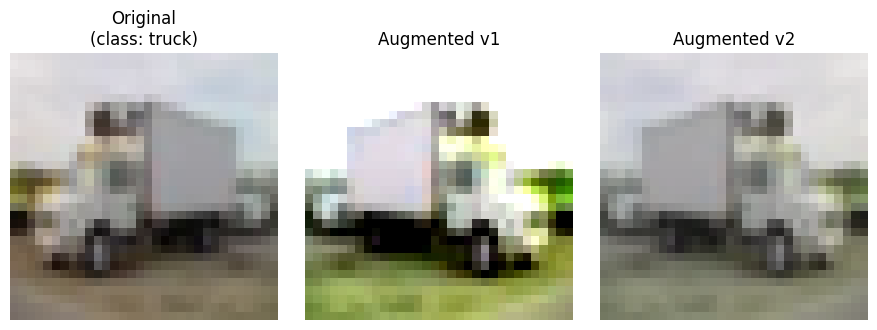

Selected test image index 1824, true class = truck


In [ ]:
rand_idx = random.randint(0, len(X_test) - 1)
raw_img = X_test[rand_idx]  # (3,32,32) uint8
pil_img = Image.fromarray(np.transpose(raw_img, (1, 2, 0)))
true_class = CLASSES[y_test[rand_idx]]

aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.9),
    transforms.ColorJitter(brightness=0.5, contrast=0.4, saturation=0.5, hue=0.2),
])

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(pil_img); axes[0].set_title(f"Original\n(class: {true_class})"); axes[0].axis("off")
axes[1].imshow(aug_transform(pil_img)); axes[1].set_title("Augmented v1"); axes[1].axis("off")
axes[2].imshow(aug_transform(pil_img)); axes[2].set_title("Augmented v2"); axes[2].axis("off")
plt.tight_layout()
plt.savefig("fig2_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Selected test image index {rand_idx}, true class = {true_class}")


**Step 5**: augmentation expands effective training variance without touching the label

### Steps 6–8 — Model Construction and Forward Pass

**Step 6**: `CIFARInception`, built from scratch with `nn.Module`. Branch channel counts are
chosen so that each `InceptionModule`'s concatenated output matches the target width at each
stage (64→112→128→224→256→304), matching the architecture table in the report.


In [ ]:
class ConvBnRelu(nn.Module):
    """Conv2d -> BatchNorm2d -> ReLU. Bias omitted (redundant given BatchNorm)."""
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

class InceptionModule(nn.Module):
    """Four parallel branches (1x1 / 3x3-reduced / 5x5-reduced / pooled-projection),
    concatenated along the channel dimension."""
    def __init__(self, in_ch, out_1x1, red_3x3, out_3x3, red_5x5, out_5x5, pool_proj):
        super().__init__()
        self.branch1 = ConvBnRelu(in_ch, out_1x1, kernel_size=1)
        self.branch2 = nn.Sequential(
            ConvBnRelu(in_ch, red_3x3, kernel_size=1),
            ConvBnRelu(red_3x3, out_3x3, kernel_size=3, padding=1))
        self.branch3 = nn.Sequential(
            ConvBnRelu(in_ch, red_5x5, kernel_size=1),
            ConvBnRelu(red_5x5, out_5x5, kernel_size=5, padding=2))
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, pool_proj, kernel_size=1))
        self.out_channels = out_1x1 + out_3x3 + out_5x5 + pool_proj

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x),
                           self.branch3(x), self.branch4(x)], dim=1)

class CIFARInception(nn.Module):
    def __init__(self, num_classes=10, dropout_p=0.4):
        super().__init__()
        self.stem = nn.Sequential(
            ConvBnRelu(3, 32, kernel_size=3, padding=1),
            ConvBnRelu(32, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2))                                             # 32->16

        self.inc1a = InceptionModule(64,  24, 32, 48,  8, 16, 24)           # -> 112
        self.inc1b = InceptionModule(112, 32, 48, 64,  8, 16, 16)           # -> 128
        self.pool1 = nn.MaxPool2d(2, 2)                                     # 16->8

        self.inc2a = InceptionModule(128, 64, 64, 96, 16, 32, 32)           # -> 224
        self.inc2b = InceptionModule(224, 64, 96, 128, 16, 32, 32)          # -> 256
        self.pool2 = nn.MaxPool2d(2, 2)                                     # 8->4

        self.inc3a = InceptionModule(256, 96, 96, 144, 16, 32, 32)          # -> 304

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(p=dropout_p)
        self.classifier = nn.Linear(304, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1); nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight); nn.init.constant_(m.bias, 0)

    def forward(self, x, return_trace=False):
        trace = {}
        x = self.stem(x);   trace["stem (after stride-2 pool)"] = x.shape
        x = self.inc1a(x);  trace["inception 1a"] = x.shape
        x = self.inc1b(x);  trace["inception 1b"] = x.shape
        x = self.pool1(x);  trace["pool 1"] = x.shape
        x = self.inc2a(x);  trace["inception 2a"] = x.shape
        x = self.inc2b(x);  trace["inception 2b"] = x.shape
        x = self.pool2(x);  trace["pool 2"] = x.shape
        x = self.inc3a(x);  trace["inception 3a"] = x.shape
        x = self.gap(x);    trace["global avg pool"] = x.shape
        x = torch.flatten(x, 1); trace["flatten"] = x.shape
        x = self.dropout(x)
        logits = self.classifier(x); trace["logits"] = logits.shape
        return (logits, trace) if return_trace else logits

model = CIFARInception(num_classes=10).to(device)

print("=== Layer-by-layer summary ===")
for name, module in model.named_children():
    n_p = sum(p.numel() for p in module.parameters())
    print(f"{name:10s} {module.__class__.__name__:18s} params={n_p:,}")

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {n_params:,}")


=== Layer-by-layer summary ===
stem       Sequential         params=19,488
inc1a      InceptionModule    params=22,960
inc1b      InceptionModule    params=42,864
pool1      MaxPool2d          params=0
inc2a      InceptionModule    params=91,232
inc2b      InceptionModule    params=170,720
pool2      MaxPool2d          params=0
inc3a      InceptionModule    params=199,488
gap        AdaptiveAvgPool2d  params=0
dropout    Dropout            params=0
classifier Linear             params=3,050

Total trainable parameters: 549,802


**Step 7**: trace tensor shapes end-to-end; extract intermediate activations from

inc2b via a forward hook and plot a 4×4 grid of feature maps for a random test image.


=== Shape trace (input 3x32x32 -> logits) ===
input                     -> (3, 32, 32)
stem (after stride-2 pool) -> (1, 64, 16, 16)
inception 1a              -> (1, 112, 16, 16)
inception 1b              -> (1, 128, 16, 16)
pool 1                    -> (1, 128, 8, 8)
inception 2a              -> (1, 224, 8, 8)
inception 2b              -> (1, 256, 8, 8)
pool 2                    -> (1, 256, 4, 4)
inception 3a              -> (1, 304, 4, 4)
global avg pool           -> (1, 304, 1, 1)
flatten                   -> (1, 304)
logits                    -> (1, 10)


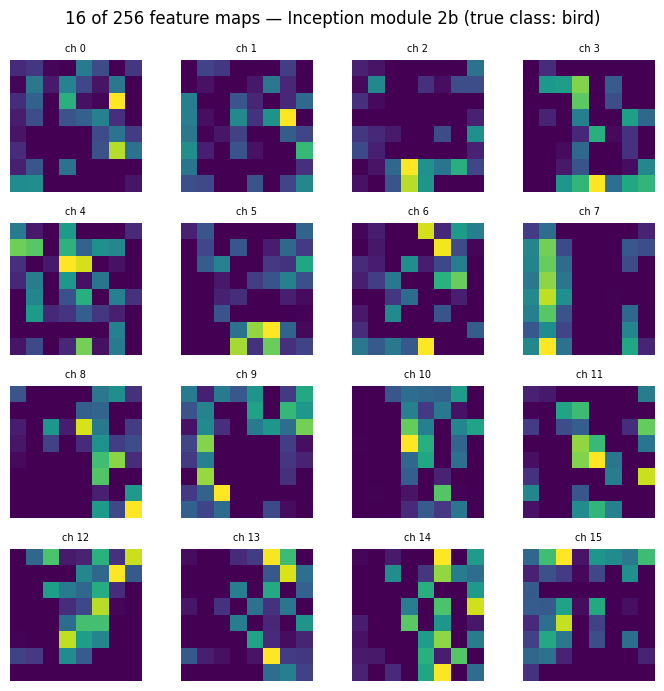

In [ ]:
sample_x, sample_y = test_ds[random.randint(0, len(test_ds) - 1)]
logits, trace = model(sample_x.unsqueeze(0).to(device), return_trace=True)

print("=== Shape trace (input 3x32x32 -> logits) ===")
print(f"{'input':25s} -> {tuple(sample_x.shape)}")
for k, v in trace.items():
    print(f"{k:25s} -> {tuple(v)}")

captured = {}
def make_hook(name):
    def hook(mod, inp, out):
        captured[name] = out.detach().cpu()
    return hook

h = model.inc2b.register_forward_hook(make_hook("inc2b"))
with torch.no_grad():
    _ = model(sample_x.unsqueeze(0).to(device))
h.remove()

fmap = captured["inc2b"][0]   # (256, 8, 8)
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i].numpy(), cmap="viridis")
    ax.set_title(f"ch {i}", fontsize=7)
    ax.axis("off")
plt.suptitle(f"16 of {fmap.shape[0]} feature maps — Inception module 2b (true class: {CLASSES[sample_y]})")
plt.tight_layout()
plt.savefig("fig3_feature_maps.png", dpi=150, bbox_inches="tight")
plt.show()


**Step 8**: discussion of spatial contraction vs. channel expansion, and how backprop
uses these exact parameters, is in the report

### Steps 9–12 — Training, Optimiser, Loss Curves

Adam + cosine annealing + label smoothing + gradient clipping, matching the report's
configuration table.


In [ ]:
EPOCHS = 35
LR = 3e-4
optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999),
                              eps=1e-8, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
           "grad_norm": [], "lr": []}
best_val_acc = 0.0
start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total, epoch_grad_norms = 0.0, 0, 0, []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        epoch_grad_norms.append(gnorm.item())
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    scheduler.step()

    train_loss, train_acc = running_loss / total, correct / total

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            val_loss += loss.item() * xb.size(0)
            val_correct += (out.argmax(1) == yb).sum().item()
            val_total += xb.size(0)
    val_loss, val_acc = val_loss / val_total, val_correct / val_total

    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)
    history["grad_norm"].append(float(np.mean(epoch_grad_norms)))
    history["lr"].append(optimizer.param_groups[0]["lr"])

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_inception_cifar10.pth")

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"| train_acc={train_acc:.4f} val_acc={val_acc:.4f} | grad_norm={history['grad_norm'][-1]:.3f}")

print(f"\nTraining time: {(time.time()-start_time)/60:.1f} min | Best val accuracy: {best_val_acc:.4f}")


Epoch 01/35 | train_loss=1.7230 val_loss=1.3918 | train_acc=0.3995 val_acc=0.5422 | grad_norm=4.056
Epoch 02/35 | train_loss=1.3918 val_loss=1.2500 | train_acc=0.5463 val_acc=0.6048 | grad_norm=4.057
Epoch 03/35 | train_loss=1.2458 val_loss=1.1383 | train_acc=0.6119 val_acc=0.6570 | grad_norm=3.880
Epoch 04/35 | train_loss=1.1466 val_loss=1.0979 | train_acc=0.6555 val_acc=0.6706 | grad_norm=3.756
Epoch 05/35 | train_loss=1.0713 val_loss=1.0071 | train_acc=0.6885 val_acc=0.7142 | grad_norm=3.576
Epoch 06/35 | train_loss=1.0041 val_loss=0.9500 | train_acc=0.7191 val_acc=0.7304 | grad_norm=3.583
Epoch 07/35 | train_loss=0.9531 val_loss=0.9109 | train_acc=0.7417 val_acc=0.7602 | grad_norm=3.564
Epoch 08/35 | train_loss=0.9087 val_loss=0.8811 | train_acc=0.7588 val_acc=0.7700 | grad_norm=3.514
Epoch 09/35 | train_loss=0.8775 val_loss=0.8474 | train_acc=0.7726 val_acc=0.7856 | grad_norm=3.455
Epoch 10/35 | train_loss=0.8466 val_loss=0.8442 | train_acc=0.7843 val_acc=0.7904 | grad_norm=3.495


**Step 11**: Adam's mathematical principles (first/second moment, bias correction,
per-parameter adaptive rate) are derived in full in the report (Step 11) — this is the
implementation only.

**Step 12**: 4-panel training diagnostics figure — loss, accuracy, gradient norm, and
learning rate schedule across epochs.


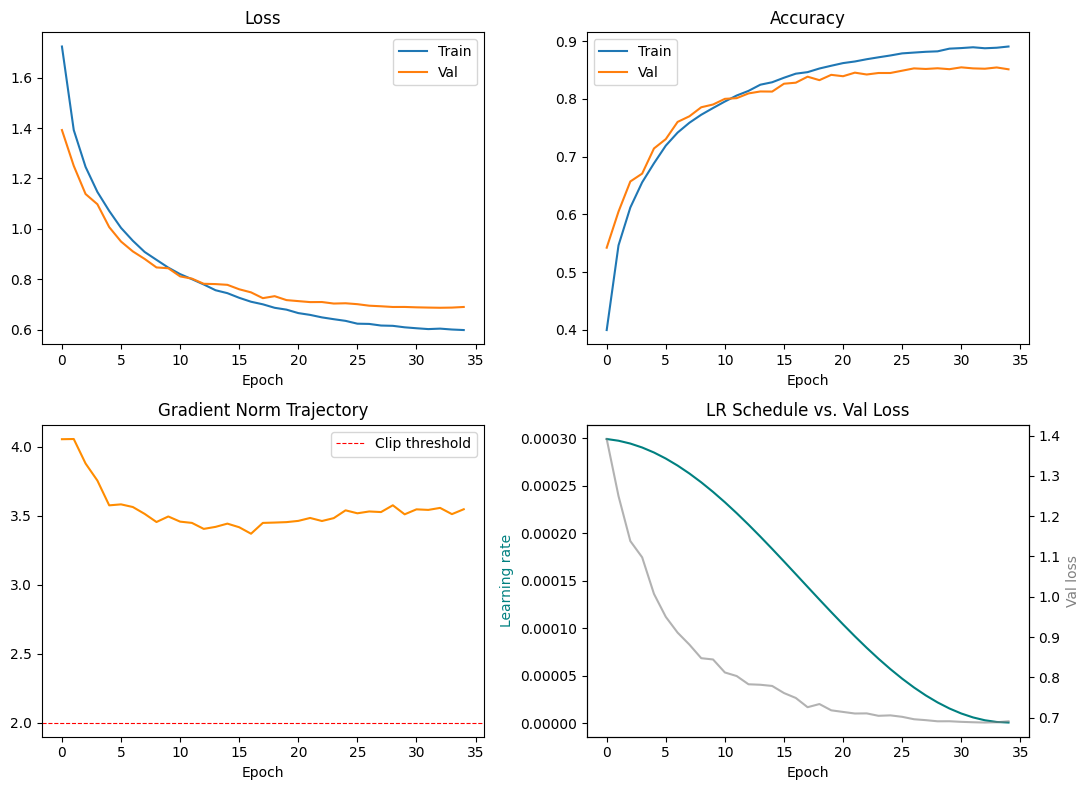

Best (min val-loss) epoch: 33 of 35


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(history["train_loss"], label="Train")
axes[0, 0].plot(history["val_loss"], label="Val")
axes[0, 0].set_title("Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend()

axes[0, 1].plot(history["train_acc"], label="Train")
axes[0, 1].plot(history["val_acc"], label="Val")
axes[0, 1].set_title("Accuracy"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend()

axes[1, 0].plot(history["grad_norm"], color="darkorange")
axes[1, 0].axhline(2.0, color="red", linestyle="--", linewidth=0.8, label="Clip threshold")
axes[1, 0].set_title("Gradient Norm Trajectory"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend()

ax2 = axes[1, 1]
ax2.plot(history["lr"], color="teal")
ax2.set_ylabel("Learning rate", color="teal")
ax2.set_title("LR Schedule vs. Val Loss"); ax2.set_xlabel("Epoch")
ax3 = ax2.twinx()
ax3.plot(history["val_loss"], color="grey", alpha=0.6)
ax3.set_ylabel("Val loss", color="grey")

plt.tight_layout()
plt.savefig("fig4_training_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Best (min val-loss) epoch: {best_epoch} of {EPOCHS}")


### Steps 13–15 — Evaluation and Error Analysis

**Step 13**: load the best checkpoint, evaluate on the official 10,000-image test set.


In [ ]:
model.load_state_dict(torch.load("best_inception_cifar10.pth", map_location=device))
model.eval()

all_preds, all_labels, all_probs = [], [], []
test_loss, test_correct, test_total = 0.0, 0, 0
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        probs = torch.softmax(out, dim=1)
        loss = criterion(out, yb)
        test_loss += loss.item() * xb.size(0)
        preds = out.argmax(1)
        test_correct += (preds == yb).sum().item()
        test_total += xb.size(0)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(yb.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)
all_probs = np.concatenate(all_probs)
test_acc, test_loss = test_correct / test_total, test_loss / test_total
print(f"TEST ACCURACY: {test_acc:.4f}   TEST LOSS: {test_loss:.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=3))


TEST ACCURACY: 0.8423   TEST LOSS: 0.7155

              precision    recall  f1-score   support

    airplane      0.824     0.867     0.845      1000
  automobile      0.933     0.922     0.928      1000
        bird      0.796     0.798     0.797      1000
         cat      0.711     0.686     0.698      1000
        deer      0.835     0.838     0.837      1000
         dog      0.771     0.769     0.770      1000
        frog      0.863     0.885     0.874      1000
       horse      0.887     0.852     0.869      1000
        ship      0.904     0.898     0.901      1000
       truck      0.897     0.908     0.903      1000

    accuracy                          0.842     10000
   macro avg      0.842     0.842     0.842     10000
weighted avg      0.842     0.842     0.842     10000



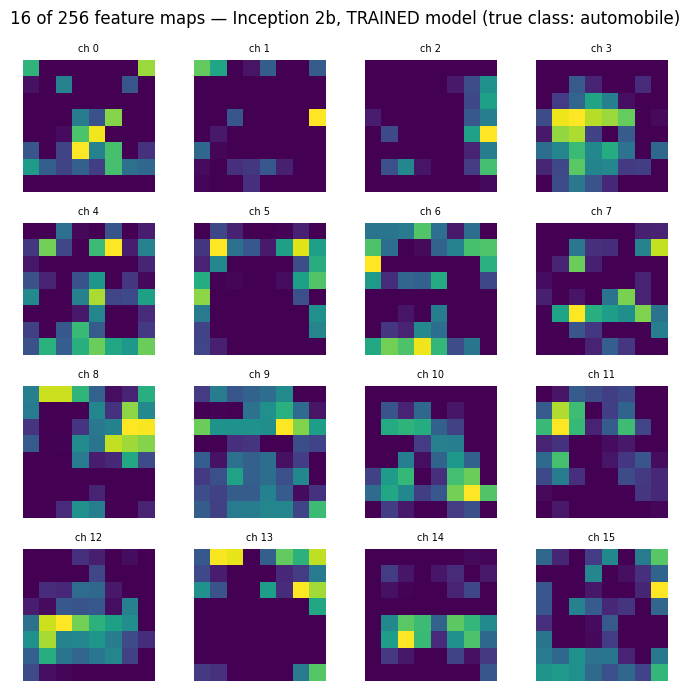

In [ ]:
# Re-capture Inception-2b feature maps using the TRAINED model (fixes the pre-training issue)
captured_trained = {}
def make_hook_trained(name):
    def hook(mod, inp, out):
        captured_trained[name] = out.detach().cpu()
    return hook

sample_x2, sample_y2 = test_ds[random.randint(0, len(test_ds) - 1)]
h2 = model.inc2b.register_forward_hook(make_hook_trained("inc2b"))
model.eval()
with torch.no_grad():
    _ = model(sample_x2.unsqueeze(0).to(device))
h2.remove()

fmap2 = captured_trained["inc2b"][0]
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap2[i].numpy(), cmap="viridis")
    ax.set_title(f"ch {i}", fontsize=7)
    ax.axis("off")
plt.suptitle(f"16 of {fmap2.shape[0]} feature maps — Inception 2b, TRAINED model (true class: {CLASSES[sample_y2]})")
plt.tight_layout()
plt.savefig("fig3_feature_maps.png", dpi=150, bbox_inches="tight")  # overwrites the untrained version
plt.show()


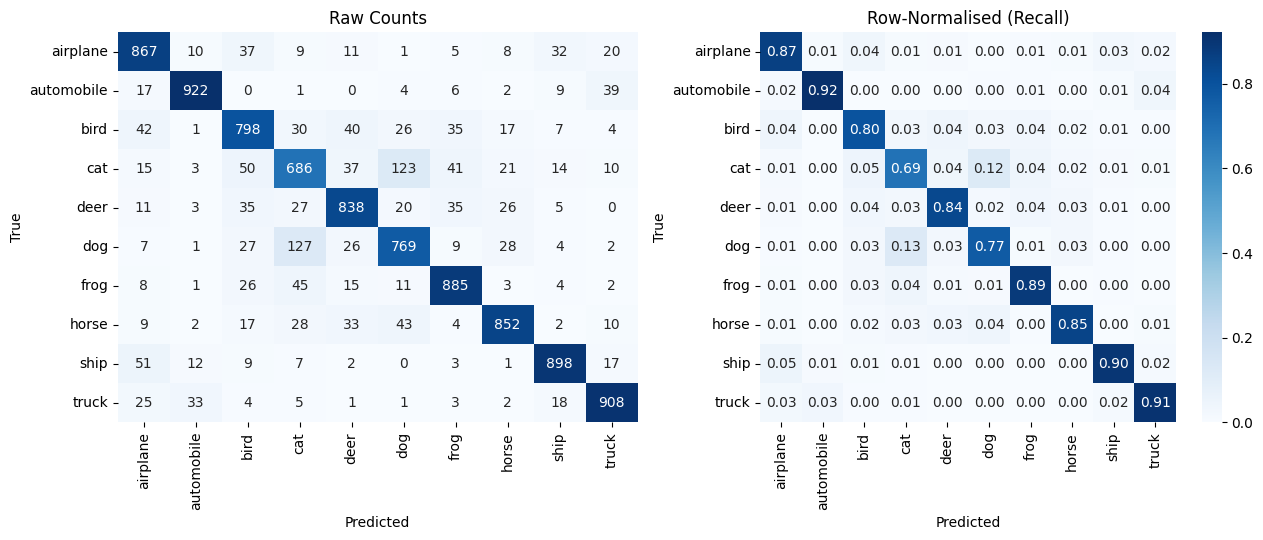

automobile   recall = 0.922
truck        recall = 0.908
ship         recall = 0.898
frog         recall = 0.885
airplane     recall = 0.867
horse        recall = 0.852
deer         recall = 0.838
bird         recall = 0.798
dog          recall = 0.769
cat          recall = 0.686


In [ ]:
cm_counts = confusion_matrix(all_labels, all_preds)
cm_norm = confusion_matrix(all_labels, all_preds, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.heatmap(cm_counts, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
axes[0].set_title("Raw Counts"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Row-Normalised (Recall)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")

plt.tight_layout()
plt.savefig("fig5_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

per_class_recall = cm_norm.diagonal()
for cls, r in sorted(zip(CLASSES, per_class_recall), key=lambda t: -t[1]):
    print(f"{cls:12s} recall = {r:.3f}")


**Step 14**: isolate the top-9 highest-confidence misclassifications (ranked by the
probability the model assigned to its *wrong* prediction).


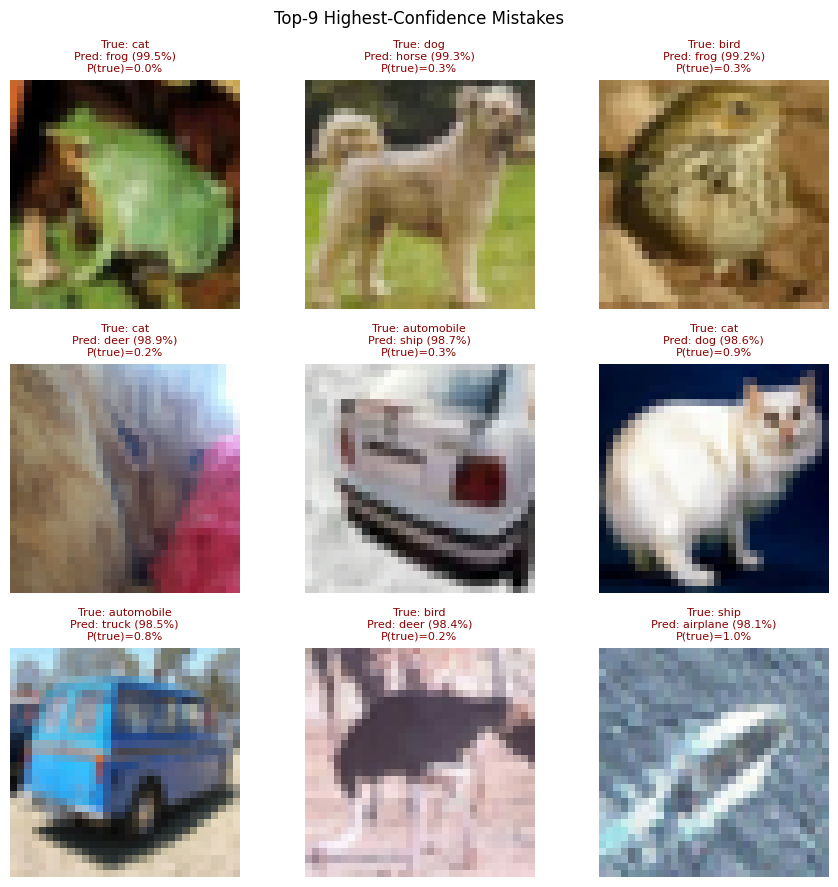

Rank | True | Predicted | Confidence | P(True Class)
   1 | cat        | frog       |  99.48% |  0.04%
   2 | dog        | horse      |  99.25% |  0.29%
   3 | bird       | frog       |  99.17% |  0.30%


In [ ]:
wrong_mask = (all_preds != all_labels)
wrong_idxs = np.where(wrong_mask)[0]
wrong_conf = all_probs[wrong_idxs, all_preds[wrong_idxs]]
order = np.argsort(wrong_conf)[::-1]
top_wrong = wrong_idxs[order[:9]]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, idx in zip(axes.flat, top_wrong):
    img, true_label = test_ds[idx]
    denorm = np.clip(img.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)
    pred_label = all_preds[idx]
    conf = all_probs[idx, pred_label]
    p_true = all_probs[idx, true_label]
    ax.imshow(denorm)
    ax.set_title(f"True: {CLASSES[true_label]}\nPred: {CLASSES[pred_label]} ({conf*100:.1f}%)\n"
                 f"P(true)={p_true*100:.1f}%", fontsize=8, color="darkred")
    ax.axis("off")
plt.suptitle("Top-9 Highest-Confidence Mistakes")
plt.tight_layout()
plt.savefig("fig6_top9_mistakes.png", dpi=150, bbox_inches="tight")
plt.show()

print("Rank | True | Predicted | Confidence | P(True Class)")
for rank, idx in enumerate(top_wrong[:3], start=1):
    _, true_label = test_ds[idx]
    pred_label = all_preds[idx]
    print(f"{rank:4d} | {CLASSES[true_label]:10s} | {CLASSES[pred_label]:10s} | "
          f"{all_probs[idx, pred_label]*100:6.2f}% | {all_probs[idx, true_label]*100:5.2f}%")


**Step 15**: in-depth error analysis (intra-class similarity at 32×32, background bias,
pose variation, label noise, architectural strengths/limits) is written up in full in the report
(Step 15) using the ranked list and confusion matrix produced above as evidence.

### Steps 16–17 — Probability Visualisation and Calibration

Five unseen test images, one per a spread of classes, with their full Top-10 Softmax
probability distribution as a horizontal bar chart (true class highlighted).


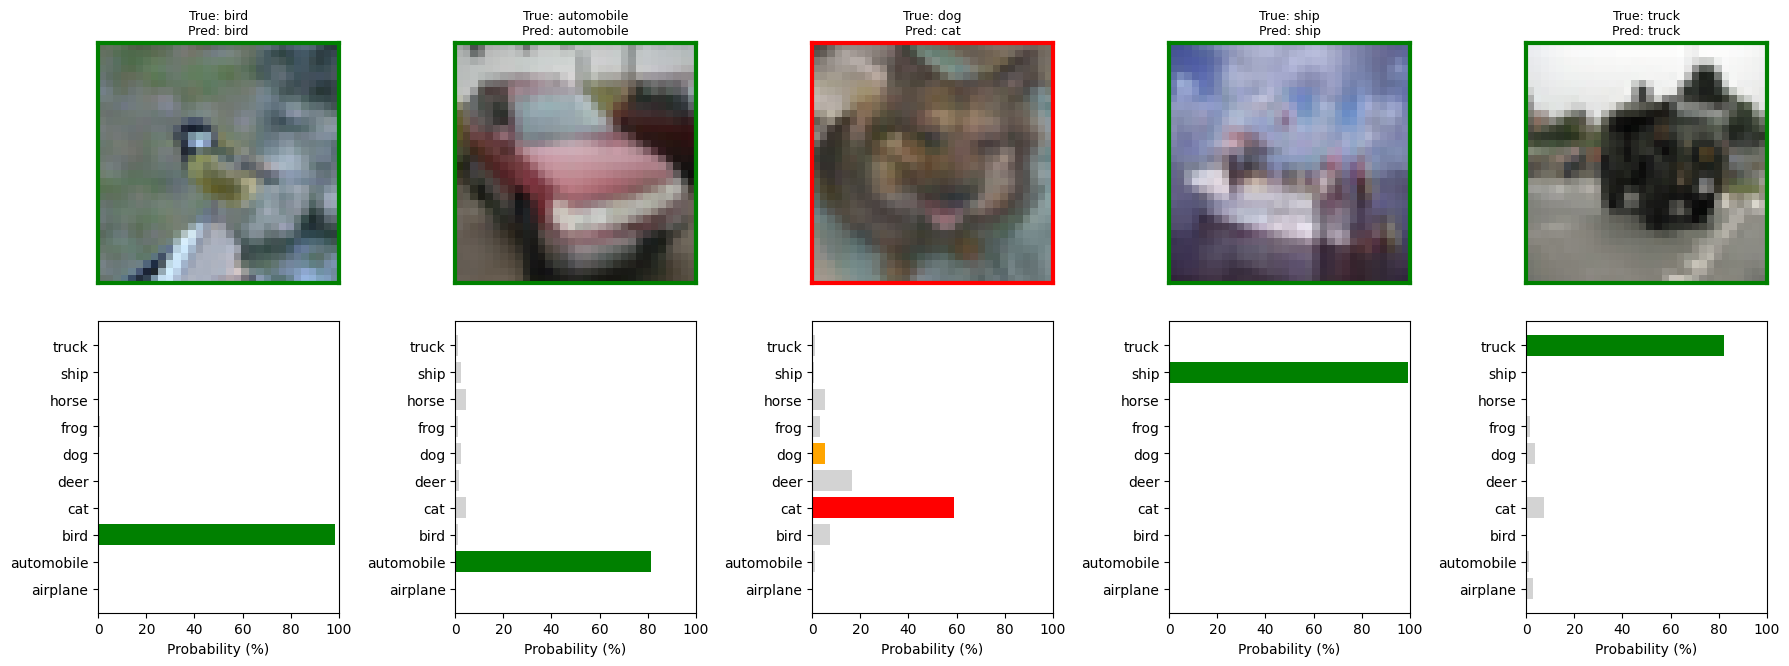

In [ ]:
chosen_idxs = []
seen_classes = set()
for idx in np.random.RandomState(SEED).permutation(len(test_ds)):
    _, lbl = test_ds[idx]
    if lbl not in seen_classes:
        chosen_idxs.append(idx); seen_classes.add(lbl)
    if len(chosen_idxs) == 5:
        break

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for col, idx in enumerate(chosen_idxs):
    img, true_label = test_ds[idx]
    probs = all_probs[idx]
    pred_label = all_preds[idx]
    correct = (pred_label == true_label)

    denorm = np.clip(img.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)
    axes[0, col].imshow(denorm)
    border_color = "green" if correct else "red"
    for spine in axes[0, col].spines.values():
        spine.set_visible(True); spine.set_color(border_color); spine.set_linewidth(3)
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([])
    axes[0, col].set_title(f"True: {CLASSES[true_label]}\nPred: {CLASSES[pred_label]}", fontsize=9)

    bar_colors = []
    for c in range(10):
        if c == true_label and correct:
            bar_colors.append("green")
        elif c == pred_label and not correct:
            bar_colors.append("red")
        elif c == true_label and not correct:
            bar_colors.append("orange")
        else:
            bar_colors.append("lightgrey")
    axes[1, col].barh(CLASSES, probs * 100, color=bar_colors)
    axes[1, col].set_xlim(0, 100)
    axes[1, col].set_xlabel("Probability (%)")

plt.tight_layout()
plt.savefig("fig7_probability_bars.png", dpi=150, bbox_inches="tight")
plt.show()


**Step 17**: the mathematical deconstruction of logits → Softmax probabilities, and why the
model can be confidently wrong (relative not absolute confidence, calibration, label smoothing
/ temperature scaling as remedies) is written up in the report (Step 17) — no additional code.



### Additional Enhancement — Quick Ablation (equal small budget)

A short comparison of the custom Inception model against a VGG-like and a plain-ResNet-like
block of comparable depth, trained for the same reduced number of epochs, purely to illustrate
the gradient-stability argument from Part 1 empirically. **Not a substitute for the main 35-epoch
run above**


In [ ]:
class VGGSmall(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBnRelu(3, 32, 3, padding=1), ConvBnRelu(32, 32, 3, padding=1), nn.MaxPool2d(2),
            ConvBnRelu(32, 64, 3, padding=1), ConvBnRelu(64, 64, 3, padding=1), nn.MaxPool2d(2),
            ConvBnRelu(64, 128, 3, padding=1), ConvBnRelu(128, 128, 3, padding=1), nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)
    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(self.gap(x), 1)
        return self.fc(x)

class ResNetSmallBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = ConvBnRelu(ch, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(ch)
    def forward(self, x):
        out = self.conv1(x)
        out = self.bn2(self.conv2(out))
        return torch.relu(out + x)

class ResNetSmall(nn.Module):
    def __init__(self, num_classes=10, ch=64, n_blocks=4):
        super().__init__()
        self.stem = ConvBnRelu(3, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ResNetSmallBlock(ch) for _ in range(n_blocks)])
        self.pool = nn.MaxPool2d(4)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(ch, num_classes)
    def forward(self, x):
        x = self.pool(self.blocks(self.stem(x)))
        x = torch.flatten(self.gap(x), 1)
        return self.fc(x)

def quick_train_eval(net, epochs=5):
    net = net.to(device)
    opt = torch.optim.Adam(net.parameters(), lr=3e-4)
    crit = nn.CrossEntropyLoss()
    for _ in range(epochs):
        net.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(net(xb), yb)
            loss.backward()
            opt.step()
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (net(xb).argmax(1) == yb).sum().item()
            total += xb.size(0)
    return correct / total

ABLATION_EPOCHS = 5   # small, equal budget for all three
results = {}
for name, net in [("VGGSmall", VGGSmall()),
                   ("ResNetSmall", ResNetSmall()),
                   ("CIFARInception (fresh)", CIFARInception())]:
    acc = quick_train_eval(net, epochs=ABLATION_EPOCHS)
    results[name] = acc
    print(f"{name:25s} test_acc={acc:.4f} (params={sum(p.numel() for p in net.parameters()):,})")


VGGSmall                  test_acc=0.7255 (params=288,746)
ResNetSmall               test_acc=0.6641 (params=298,698)
CIFARInception (fresh)    test_acc=0.7089 (params=549,802)
